In [1]:
import sys
sys.path.append('/data/user/wu_j1/bamf')

In [2]:

from analysis_codes import helpers, runners,diagnostics,analysis,plotting
import h5py,pandas as pd,numpy as np

<Figure size 2880x1008 with 0 Axes>

In [3]:
def norm_F_G(ls, F,G):
    F_norm = F[ls].apply(lambda x: x/x.sum(), axis=1)
    G_norm = G.multiply(F[ls].sum(axis=1).values,axis="columns")
    return F_norm,G_norm

In [4]:
folder = "/data/user/wu_j1/Zurich-ToF-ACSM/mz115/processed/"
filename = "input_matrices_martavia_noised_20220315_winter.h5"

# filename = "/data/user/wu_j1/bamf/data/longer_data.h5"
with h5py.File(folder+filename, "r") as f:
    # List all groups
    print("Keys: %s" % f.keys())
    group_key = list(f.keys())

Keys: <KeysViewHDF5 ['F', 'G', 'data', 'error']>


In [5]:
F = pd.read_hdf(folder+filename,"F")
data = pd.read_hdf(folder+filename,"data")
error = pd.read_hdf(folder+filename,"error")
G = pd.read_hdf(folder+filename, "G")

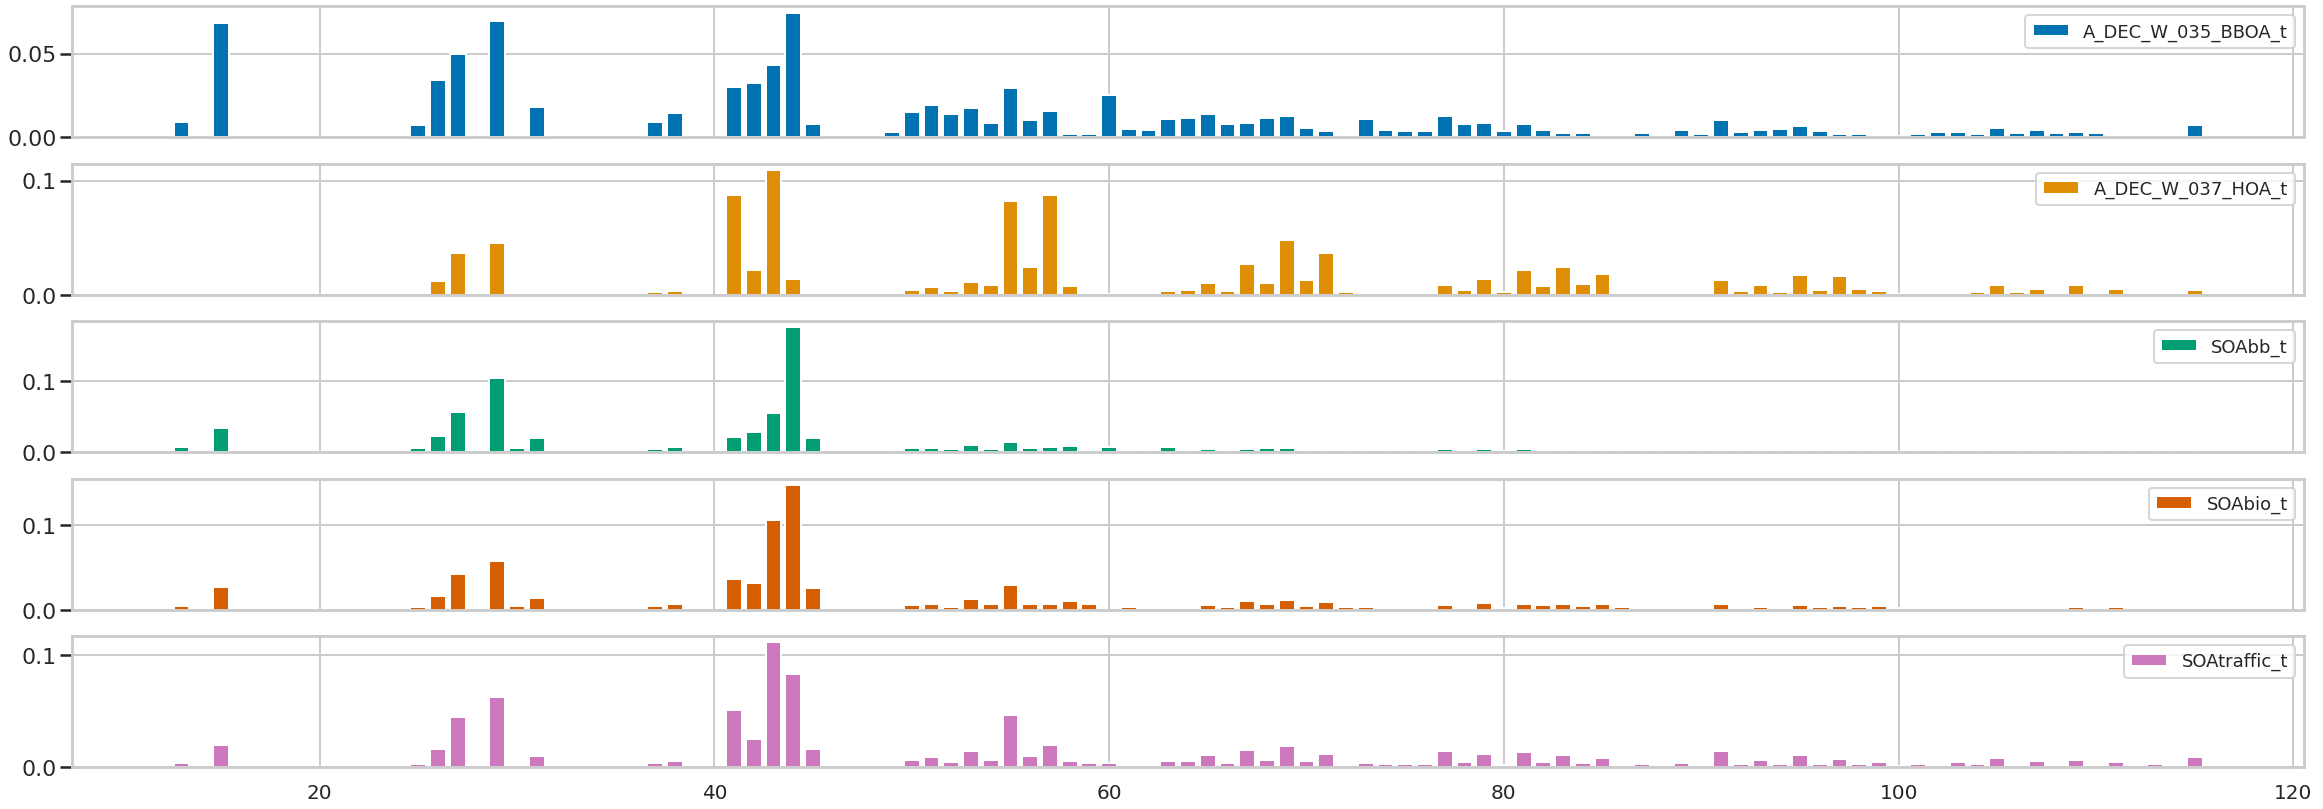

In [6]:
plotting.plot_benchmark(F,label="F")

In [7]:
F

,13.0,15.0,25.0,26.0,27.0,29.0,30.0,31.0,37.0,38.0,...,106.0,107.0,108.0,109.0,110.0,111.0,112.0,113.0,114.0,115.0
A_DEC_W_035_BBOA_t,0.009322,0.068399,0.007674,0.034137,0.049765,0.069485,0.001529,0.018221,0.009003,0.014285,...,0.002446,0.004700,0.002374,0.003166,0.002643,0.001266,0.000914,0.001389,0.001257,0.007259
A_DEC_W_037_HOA_t,0.000976,0.000256,0.001998,0.012085,0.037010,0.045581,0.001003,0.001786,0.002231,0.003822,...,0.002500,0.005377,0.001912,0.008730,0.001968,0.005539,0.001378,0.001917,0.000526,0.003932
SOAbb_t,0.007148,0.034868,0.005478,0.023328,0.056495,0.104109,0.005872,0.020471,0.004797,0.007801,...,0.000537,0.000810,0.000603,0.001057,0.000635,0.000698,0.000496,0.000693,0.000361,0.001451
SOAbio_t,0.003991,0.026879,0.003297,0.015964,0.041751,0.056918,0.004530,0.013482,0.003949,0.007056,...,0.000882,0.002183,0.001506,0.002969,0.001840,0.003155,0.001603,0.002136,0.001127,0.002381
SOAtraffic_t,0.003622,0.020022,0.002888,0.016335,0.045164,0.062824,0.001382,0.010218,0.003422,0.005889,...,0.002054,0.005804,0.002370,0.006094,0.002101,0.004894,0.001656,0.002601,0.001216,0.008837


(array([64.,  9.,  2.,  3.,  1.,  2.,  0.,  0.,  0.,  1.]),
 array([0.00041847, 0.00674922, 0.01307996, 0.01941071, 0.02574145,
        0.03207219, 0.03840294, 0.04473368, 0.05106443, 0.05739517,
        0.06372592]),
 <BarContainer object of 10 artists>)

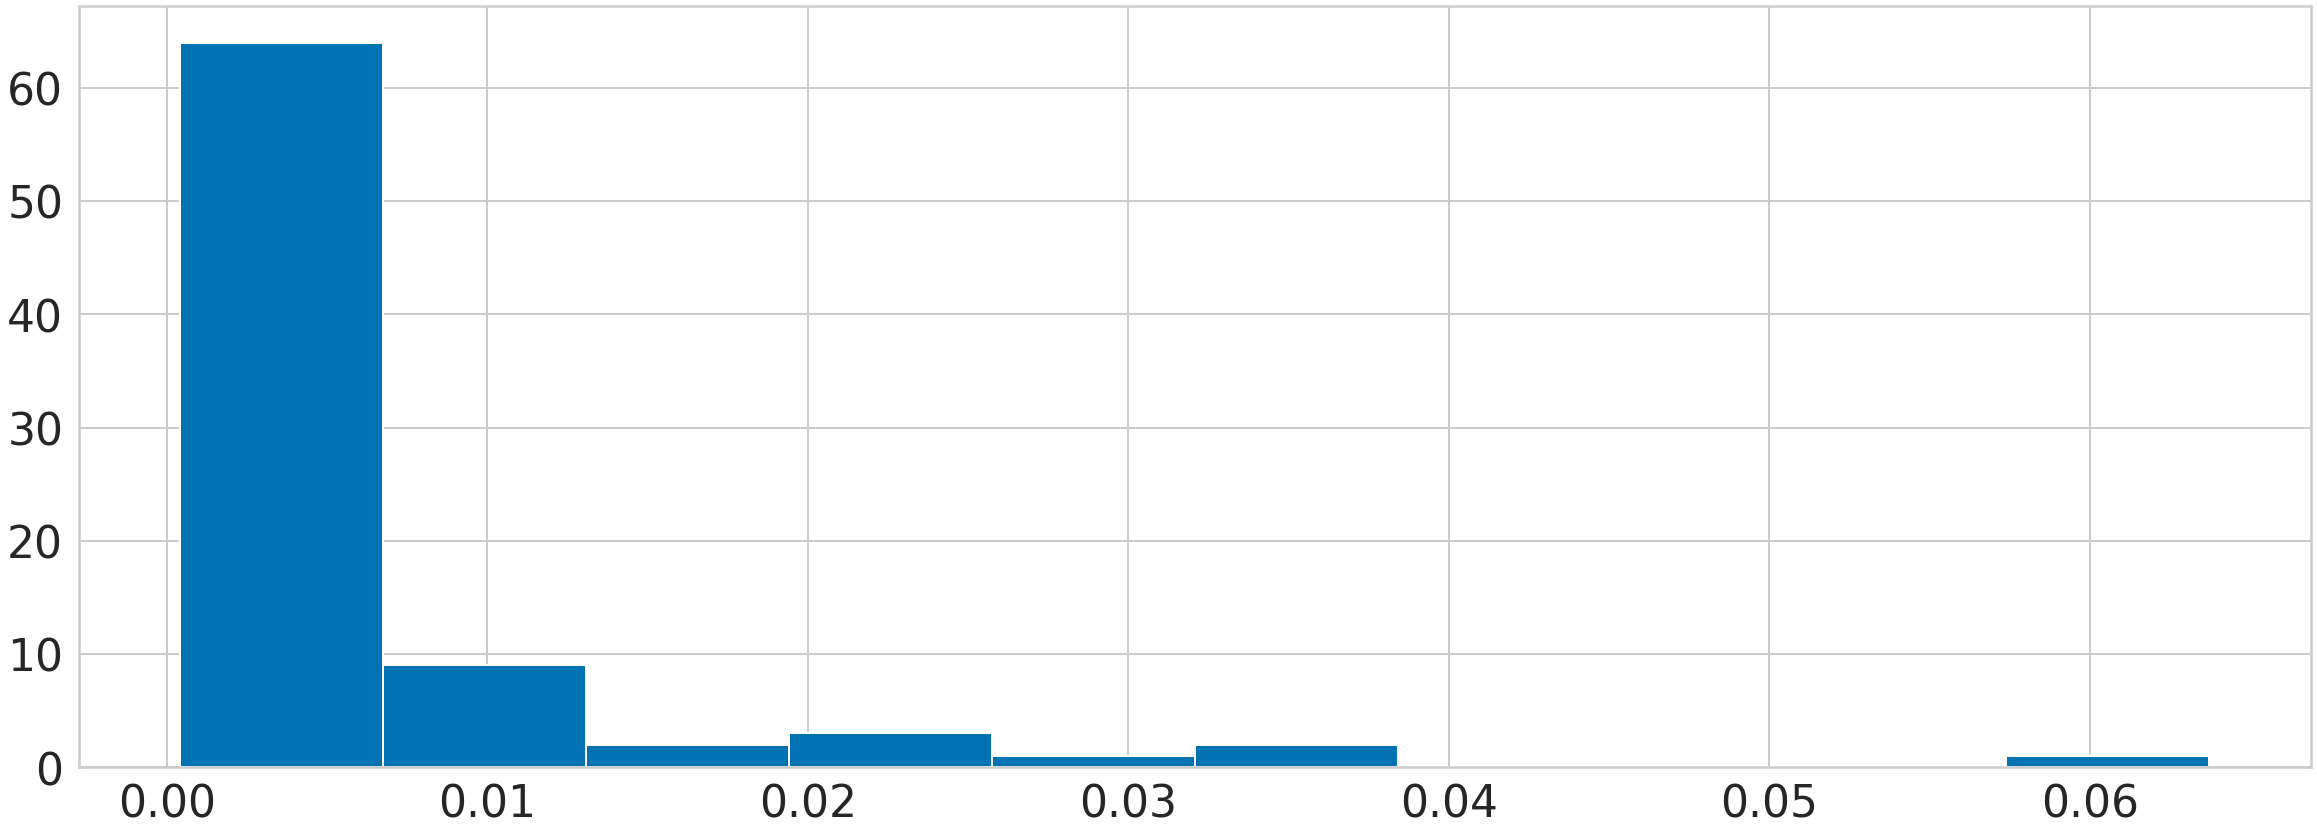

In [8]:
plotting.plt.hist(F.std().values)

In [9]:
selected_ls = np.array(F.std()[F.std() > 0.01].index)

selected_ls

array([15., 29., 41., 43., 44., 55., 57., 60., 69., 71.])

In [10]:
# F_norm = F[selected_ls].apply(lambda x: x/x.sum(), axis=1)
# G_norm = G.multiply(F[selected_ls].sum(axis=1).values,axis="columns")
F_norm,G_norm = norm_F_G(selected_ls, F,G)

In [11]:
partial_const=pd.DataFrame([data.sum(axis=1).values/data.filter(items=selected_ls).sum(axis=1).values],columns=data.index,index=["partial_const"]).T

partial_const

,partial_const
2011-02-01 00:00:00,2.123727
2011-02-01 01:00:00,2.123888
2011-02-01 02:00:00,2.126624
2011-02-01 03:00:00,2.127945
2011-02-01 04:00:00,2.130471
...,...
2011-03-31 19:00:00,2.030070
2011-03-31 20:00:00,2.021251
2011-03-31 21:00:00,2.007823
2011-03-31 22:00:00,1.992410


In [12]:
# F_norm.to_hdf(folder+'input_winter_partialmz.h5', key='F', mode='w')
# data.filter(items=selected_ls).to_hdf(folder+'input_winter_partialmz.h5', key='data', mode='r+')
# error.filter(items=selected_ls).to_hdf(folder+'input_winter_partialmz.h5', key='error', mode='r+')
# G_norm.to_hdf(folder+'input_winter_partialmz.h5', key='G', mode='r+')

# F.to_hdf(folder+'input_winter_partialmz.h5', key='F_unnorm', mode='r+')
# G.to_hdf(folder+'input_winter_partialmz.h5', key='G_unnorm', mode='r+')
# partial_const.to_hdf(folder+'input_winter_partialmz.h5', key='partial_const', mode='r+')

# manually selected mzs

In [14]:

ls_manual = [29,43,44,55,57,60,82,91]


F_norm_manual,G_norm_manual = norm_F_G(ls_manual, F,G)

partial_const_manual=pd.DataFrame([data.sum(axis=1).values/data.filter(items=ls_manual).sum(axis=1).values],columns=data.index,index=["partial_const"]).T


# F_norm_manual.to_hdf(folder+'input_winter_partialmz_mamual.h5', key='F', mode='w')
# data.filter(items=ls_manual).to_hdf(folder+'input_winter_partialmz_mamual.h5', key='data', mode='r+')
# error.filter(items=ls_manual).to_hdf(folder+'input_winter_partialmz_mamual.h5', key='error', mode='r+')
# G_norm_manual.to_hdf(folder+'input_winter_partialmz_mamual.h5', key='G', mode='r+')

                     
# F[ls_manual].to_hdf(folder+'input_winter_partialmz_mamual.h5', key='F_unnorm', mode='r+')
# G.to_hdf(folder+'input_winter_partialmz_mamual.h5', key='G_unnorm', mode='r+')
# partial_const_manual.to_hdf(folder+'input_winter_partialmz_mamual.h5', key='partial_const', mode='r+')

# Select mz based on G*F

$$EV_{j,k} = \frac{\sum_{i=1}^{n}(\left|g_{ik}\cdot f_{kj} \right|/\sigma _{ij})}{\sum_{i=1}^{n}((\sum_{h=1}^{p}\left|g_{ih}\cdot f_{hj} \right| +\theta _{ij})/\sigma _{ij})}$$

In [12]:
total = (np.dot(G,F)/error).sum(axis=0).to_frame().T
total

,13,15,25,26,27,29,30,31,37,38,...,106,107,108,109,110,111,112,113,114,115
0,66383.472946,190006.49751,74152.226164,199073.498837,281317.040826,178495.870096,15478.866246,98258.094627,80277.879022,121945.934094,...,76390.24609,125388.704691,77344.536999,135361.036451,82044.753967,105538.06837,56876.185686,74163.066374,49273.496875,147390.271684


In [13]:
explained_var=pd.concat([((np.outer(G.iloc[:,i],F.iloc[i,:])/error).sum(axis=0).to_frame().T)/total for i in range(5)],axis=0).set_axis(G.columns,axis=0)

In [14]:
explained_var

,13,15,25,26,27,29,30,31,37,38,...,106,107,108,109,110,111,112,113,114,115
BBOA_ts,0.536151,0.629416,0.516181,0.491568,0.346530,0.325659,0.186355,0.439468,0.546644,0.531178,...,0.428898,0.387526,0.420749,0.235756,0.440829,0.145573,0.262611,0.276043,0.449360,0.472520
HOA_ts,0.038811,0.001633,0.092848,0.119838,0.177137,0.147930,0.084876,0.029831,0.093652,0.098098,...,0.300766,0.302926,0.232632,0.442316,0.225519,0.433550,0.271898,0.261081,0.129651,0.175138
SOAbb_ts,0.242723,0.189439,0.217645,0.196386,0.228643,0.290801,0.430132,0.292969,0.172792,0.170952,...,0.055564,0.039015,0.062750,0.045877,0.062283,0.046557,0.083339,0.080153,0.076004,0.054836
SOAbio_ts,0.094442,0.101901,0.091422,0.095105,0.118951,0.109040,0.225001,0.132552,0.098676,0.108002,...,0.064877,0.075516,0.110123,0.092263,0.126125,0.147656,0.185571,0.171364,0.163455,0.065217
SOAtraffic_ts,0.087873,0.077611,0.081905,0.097103,0.128739,0.126571,0.073636,0.105180,0.088236,0.091771,...,0.149897,0.195018,0.173746,0.183787,0.145243,0.226664,0.196581,0.211360,0.181530,0.232289


(array([ 2.,  8., 13., 23., 14., 11.,  7.,  3.,  0.,  1.]),
 array([0.03679916, 0.06712633, 0.0974535 , 0.12778067, 0.15810785,
        0.18843502, 0.21876219, 0.24908936, 0.27941653, 0.30974371,
        0.34007088]),
 <BarContainer object of 10 artists>)

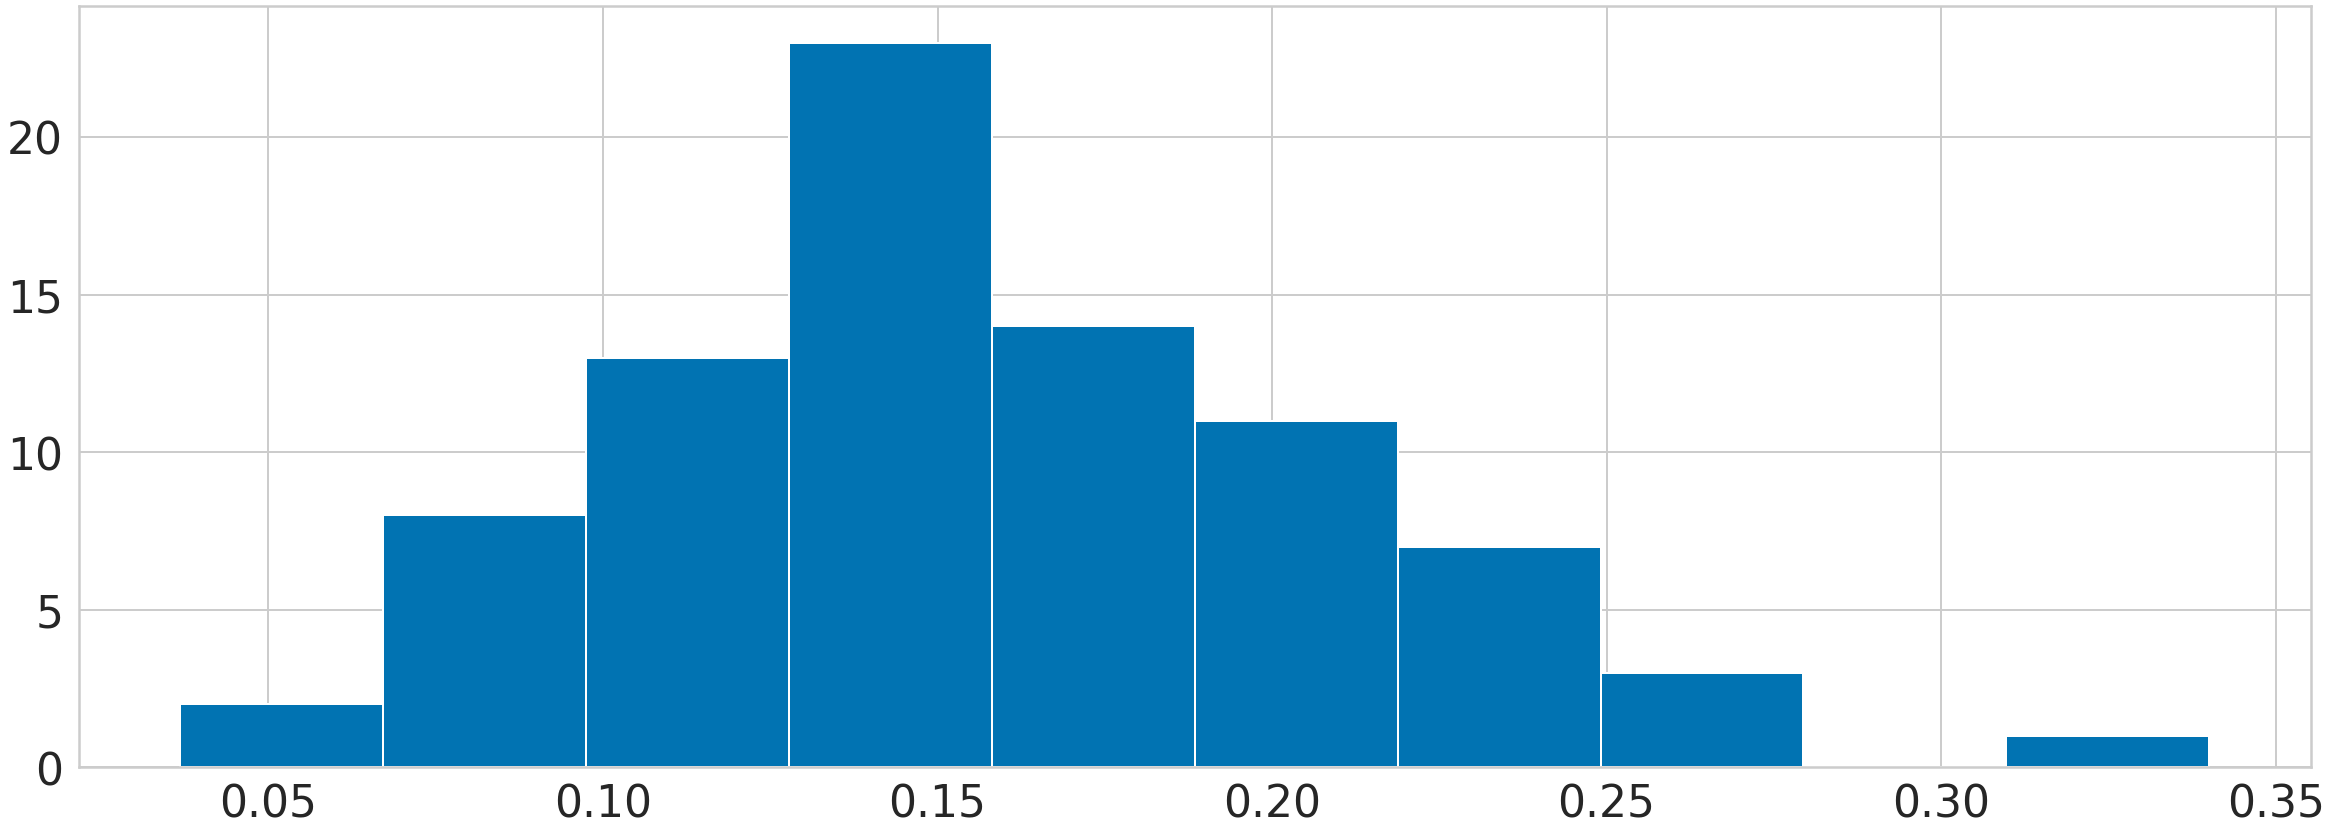

In [15]:
plotting.plt.hist(explained_var.std().values)

In [16]:
selected_ls_GF = np.array(explained_var.std()[explained_var.std() > 0.22].index)
selected_ls_GF,selected_ls_GF.shape

(array([15, 49, 52, 57, 60, 61, 62, 64, 71, 73, 83]), (11,))

In [18]:
F_norm_GF,G_norm_GF = norm_F_G(selected_ls_GF, F,G)

partial_const_GF=pd.DataFrame([data.sum(axis=1).values/data.filter(items=selected_ls_GF).sum(axis=1).values],columns=data.index,index=["partial_const"]).T


# F_norm_GF.to_hdf(folder+'input_winter_partialmz_GF.h5', key='F', mode='w')
# data.filter(items=selected_ls_GF).to_hdf(folder+'input_winter_partialmz_GF.h5', key='data', mode='r+')
# error.filter(items=selected_ls_GF).to_hdf(folder+'input_winter_partialmz_GF.h5', key='error', mode='r+')
# G_norm_GF.to_hdf(folder+'input_winter_partialmz_GF.h5', key='G', mode='r+')

                     
# F[selected_ls_GF].to_hdf(folder+'input_winter_partialmz_GF.h5', key='F_unnorm', mode='r+')
# G.to_hdf(folder+'input_winter_partialmz_GF.h5', key='G_unnorm', mode='r+')
# partial_const_GF.to_hdf(folder+'input_winter_partialmz_GF.h5', key='partial_const', mode='r+')

# get the original G from G'

In [19]:
partial_const = pd.read_hdf(folder+'input_winter_partialmz.h5', key='partial_const')
partial_const

,partial_const
2011-02-01 00:00:00,2.123727
2011-02-01 01:00:00,2.123888
2011-02-01 02:00:00,2.126624
2011-02-01 03:00:00,2.127945
2011-02-01 04:00:00,2.130471
...,...
2011-03-31 19:00:00,2.030070
2011-03-31 20:00:00,2.021251
2011-03-31 21:00:00,2.007823
2011-03-31 22:00:00,1.992410


In [5]:
import numpy as np
import xarray as xr
import pandas as pd

nc_file = "/data/user/wu_j1/bamf/run_job/partialmz/plot/mz115_partialmz/5_basic_datafile-input_winter_partialmz.nc4"
xarray = xr.open_dataset(nc_file)
xarray

<xarray.Dataset>
Dimensions:      (samples: 4000, labels: 5, variable: 10, timestep: 1416, orig_labels: 5)
Coordinates:
  * samples      (samples) int64 0 1 2 3 4 5 6 ... 3994 3995 3996 3997 3998 3999
  * labels       (labels) object 'A_DEC_W_035_BBOA_t' ... 'SOAtraffic_t'
  * variable     (variable) object '15.0' '29.0' '41.0' ... '60.0' '69.0' '71.0'
  * timestep     (timestep) datetime64[ns] 2011-02-01 ... 2011-03-31T23:00:00
  * orig_labels  (orig_labels) object 'A_DEC_W_035_BBOA_t' ... 'SOAtraffic_t'
Data variables:
    F            (samples, labels, variable) float64 ...
    G            (samples, timestep, labels) float64 ...
    X            (timestep, variable) float64 ...
    error        (timestep, variable) float64 ...
    alpha_a      (samples, labels) float64 ...
    alpha_b      (samples, labels) float64 ...
    G_orig       (timestep, orig_labels) float64 ...
    F_orig       (orig_labels, variable) float64 ...

In [3]:
G = xr.open_dataset(nc_file)["G"].values
G

array([[[1.00778129, 0.75407868, 0.51285323, 0.03441074, 0.51214502],
        [0.96670458, 0.66859653, 0.49268516, 0.03003987, 0.46922398],
        [0.97470212, 0.59307391, 0.49988703, 0.02072238, 0.49175665],
        ...,
        [0.2394335 , 0.66302206, 0.32369133, 0.95535733, 0.07899797],
        [0.16586029, 0.57608227, 0.315292  , 0.97978877, 0.09660274],
        [0.11446365, 0.52028974, 0.34357105, 1.00119054, 0.10908294]],

       [[0.79649778, 0.88347911, 0.64946003, 0.04620053, 0.4342061 ],
        [0.75627793, 0.75904257, 0.65085624, 0.0291577 , 0.42955519],
        [0.78162361, 0.69306072, 0.62361201, 0.03499615, 0.44556147],
        ...,
        [0.18198587, 0.65142967, 0.36906716, 0.96591532, 0.10124403],
        [0.10150716, 0.58407932, 0.43845322, 0.98159917, 0.03754818],
        [0.08975182, 0.53331306, 0.41847737, 1.0376737 , 0.01221752]],

       [[1.01549329, 0.73806018, 0.50341419, 0.02800095, 0.52265938],
        [0.98136312, 0.61945621, 0.50099065, 0.02371196, 0.5

In [6]:
G_median=pd.DataFrame(np.median(G,axis=0), columns= xr.open_dataset(nc_file)["labels"].values,index =xr.open_dataset(nc_file)["timestep"].values)

In [21]:
G_median

,A_DEC_W_035_BBOA_t,A_DEC_W_037_HOA_t,SOAbb_t,SOAbio_t,SOAtraffic_t
2011-02-01 00:00:00,0.793668,0.902039,0.620766,0.040490,0.440293
2011-02-01 01:00:00,0.767541,0.776252,0.608600,0.038592,0.423792
2011-02-01 02:00:00,0.781756,0.719797,0.620644,0.037657,0.416152
2011-02-01 03:00:00,0.764704,0.681613,0.594063,0.032315,0.395671
2011-02-01 04:00:00,0.790413,0.783744,0.587178,0.028197,0.396491
...,...,...,...,...,...
2011-03-31 19:00:00,0.203124,0.816132,0.310117,0.775998,0.103430
2011-03-31 20:00:00,0.222148,0.730807,0.362087,0.944790,0.101833
2011-03-31 21:00:00,0.183393,0.612730,0.385926,0.972539,0.105667
2011-03-31 22:00:00,0.124492,0.529815,0.391314,0.996668,0.099985


In [22]:
G_median*partial_const.values

,A_DEC_W_035_BBOA_t,A_DEC_W_037_HOA_t,SOAbb_t,SOAbio_t,SOAtraffic_t
2011-02-01 00:00:00,1.685533,1.915685,1.318336,0.085991,0.935062
2011-02-01 01:00:00,1.630170,1.648673,1.292598,0.081964,0.900087
2011-02-01 02:00:00,1.662501,1.530738,1.319875,0.080083,0.884998
2011-02-01 03:00:00,1.627249,1.450436,1.264133,0.068766,0.841965
2011-02-01 04:00:00,1.683952,1.669744,1.250966,0.060072,0.844713
...,...,...,...,...,...
2011-03-31 19:00:00,0.412355,1.656804,0.629560,1.575331,0.209971
2011-03-31 20:00:00,0.449017,1.477143,0.731869,1.909657,0.205829
2011-03-31 21:00:00,0.368221,1.230253,0.774871,1.952686,0.212161
2011-03-31 22:00:00,0.248038,1.055608,0.779658,1.985771,0.199211


In [23]:
G_norm*partial_const.values

NameError: name 'G_norm' is not defined

In [20]:
G_norm*partial_const.values

NameError: name 'G_norm' is not defined